# Exercise 3: Hierarchical clustering

Same images and embeddings as Exercise 1, layer 6.

## 1. Load the dataset

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset
from huggingface_hub import hf_hub_download

DATA = "blanchon/UC_Merced"

ds = load_dataset(DATA, split="train")
class_names = ds.features["label"].names
labels = np.array(ds["label"])

print(f"{len(ds)} images, {len(class_names)} classes")

2100 images, 21 classes


## 2. Embeddings

In [2]:
order = np.asarray(sorted(range(len(ds)), key=lambda i: (class_names[labels[i]], i)))
y_all = labels[order] + 1                      # 1-based, as in the embeddings

rng = np.random.default_rng(0)
train_idx, test_idx = [], []
for label in range(1, len(class_names) + 1):
    idx = np.where(y_all == label)[0]
    rng.shuffle(idx)
    n_test = max(1, int(round(len(idx) * 0.2)))
    test_idx += list(idx[:n_test])
    train_idx += list(idx[n_test:])

train_idx, test_idx = np.asarray(train_idx), np.asarray(test_idx)

print(f"train {len(train_idx)} / test {len(test_idx)}")

train 1680 / test 420


## 3. Align the training images

In [3]:
def to_rgb(row):
    im = row["image"].convert("RGB")
    if im.size != (256, 256):
        im = im.resize((256, 256))
    return np.asarray(im)

X_train_rgb = np.stack([to_rgb(ds[int(i)]) for i in order[train_idx]])
y_train = y_all[train_idx]

print(X_train_rgb.shape, y_train.shape)

(1680, 256, 256, 3) (1680,)


## 4. Load the embeddings

In [4]:
REPO = "MustafaArikan/vit_embeddings_uc_merced_layers"
path = hf_hub_download(REPO, "vit_embeddings_uc_merced_layers.npz", repo_type="dataset")
d = np.load(path)

LAYER = 6
E = d[f"E_train_l{LAYER}"]

print(E.shape)

(1680, 768)


## 5. TODO: calculate the similarity matrix using the layer 6 embedding

In [5]:
norms = np.linalg.norm(E, axis=1, keepdims=True)   
E_unit = E / norms                                 
S = E_unit @ E_unit.T                              

print(S.shape)   # (1680, 1680)

(1680, 1680)


## 6. TODO: show the most dissimilar pair and the most similar pair, using cosine similarity (without considering duplicates)

most similar:    images 145, 147  cos = 1.000
most dissimilar: images 6, 578  cos = 0.636


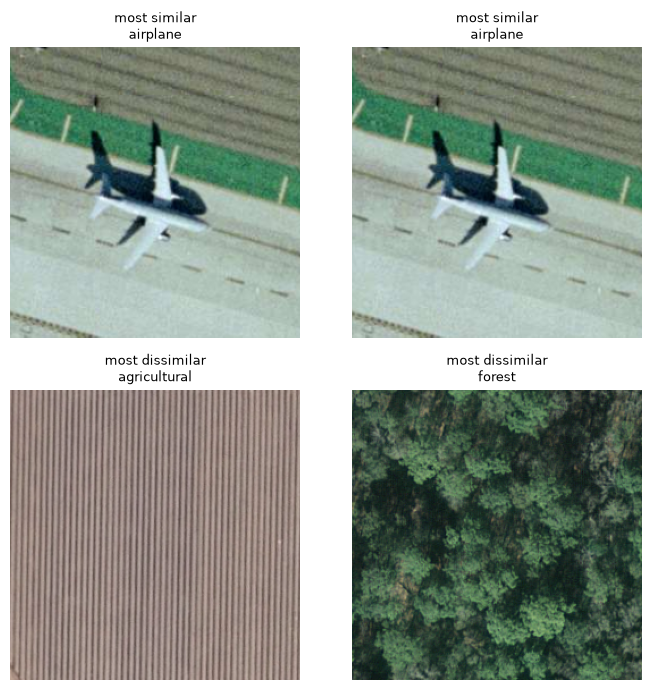

In [6]:
N = len(S)
rows, cols = np.triu_indices(N, k=1)    
vals = S[rows, cols]                    

most_similar = vals.argmax()
most_dissimilar = vals.argmin()

i1, j1 = rows[most_similar], cols[most_similar]
i2, j2 = rows[most_dissimilar], cols[most_dissimilar]

print(f"most similar:    images {i1}, {j1}  cos = {S[i1, j1]:.3f}")
print(f"most dissimilar: images {i2}, {j2}  cos = {S[i2, j2]:.3f}")

fig, ax = plt.subplots(2, 2, figsize=(7, 7))
for a, k, title in [(ax[0, 0], i1, "most similar"), (ax[0, 1], j1, "most similar"),
                    (ax[1, 0], i2, "most dissimilar"), (ax[1, 1], j2, "most dissimilar")]:
    a.imshow(X_train_rgb[k])
    a.set_title(f"{title}\n{class_names[y_train[k] - 1]}", fontsize=9)
    a.axis("off")
plt.tight_layout()
plt.show()

## 7. TODO: do hierarchical clustering, experiment with parameter settings, visualize and find a meaningful cluster

In [7]:
from scipy.cluster.hierarchy import linkage, fcluster


Z = linkage(E_unit, method="ward")                      
clusters = fcluster(Z, t=10, criterion="maxclust")       
print("cluster sizes:", np.bincount(clusters)[1:])

cluster sizes: [267 133 155 164 162 203 140 319  68  69]


In [8]:
def show_purity(clusters):
    for c in np.unique(clusters):
        members = np.where(clusters == c)[0]
        counts = np.bincount(y_train[members] - 1, minlength=len(class_names))
        top = counts.argmax()
        print(f"  cluster {c:2}: {len(members):4} images, top: {class_names[top]:16} {counts[top] / len(members):.0%}")

for method in ["single", "complete", "average", "ward"]:
    Z = linkage(E_unit, method=method)
    clusters = fcluster(Z, t=10, criterion="maxclust")
    print(method, "sizes:", np.bincount(clusters)[1:])
    show_purity(clusters)

single sizes: [   3    6    2    5    2 1653    1    2    5    1]
  cluster  1:    3 images, top: agricultural     100%
  cluster  2:    6 images, top: chaparral        100%
  cluster  3:    2 images, top: agricultural     100%
  cluster  4:    5 images, top: harbor           100%
  cluster  5:    2 images, top: agricultural     100%
  cluster  6: 1653 images, top: airplane         5%
  cluster  7:    1 images, top: forest           100%
  cluster  8:    2 images, top: agricultural     100%
  cluster  9:    5 images, top: agricultural     100%
  cluster 10:    1 images, top: forest           100%
complete sizes: [ 33 305 335  95 359  77 115 108 190  63]
  cluster  1:   33 images, top: agricultural     100%
  cluster  2:  305 images, top: beach            25%
  cluster  3:  335 images, top: overpass         13%
  cluster  4:   95 images, top: storagetanks     23%
  cluster  5:  359 images, top: tenniscourt      14%
  cluster  6:   77 images, top: chaparral        96%
  cluster  7:  115 

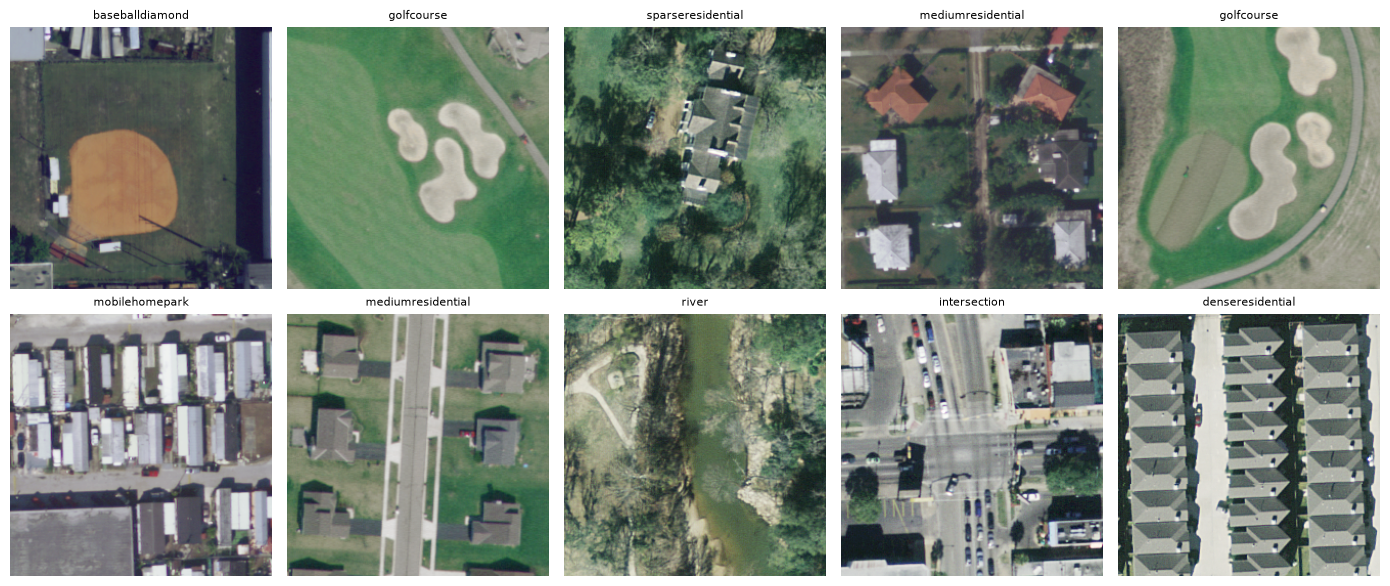

In [9]:
c = 1                                   
members = np.where(clusters == c)[0]
pick = np.random.choice(members, size=min(10, len(members)), replace=False)

fig, ax = plt.subplots(2, 5, figsize=(14, 6))
for a, j in zip(ax.flatten(), pick):
    a.imshow(X_train_rgb[j])
    a.set_title(class_names[y_train[j] - 1], fontsize=8)
    a.axis("off")
plt.tight_layout()
plt.show()